# Koneksi Neo4j

In [1]:
from neo4j import GraphDatabase
import getpass

uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "uts_graf_sains_data_2026"

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="neo4j")

# Membaca events.csv

In [2]:
import os

csv_file_path = os.path.join("data", "events.csv")

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(
        f"Error: File '{csv_file_path}' tidak ditemukan!"
    )

print(f"File ditemukan: {csv_file_path}")

File ditemukan: data\events.csv


# Rentang tanggal Dataset

In [3]:
import pandas as pd

df = pd.read_csv("data/events.csv")

df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

print("Tanggal paling awal:", df["datetime"].min())
print("Tanggal paling akhir:", df["datetime"].max())

Tanggal paling awal: 2015-05-03 03:00:04.384000+00:00
Tanggal paling akhir: 2015-09-18 02:59:47.788000+00:00


# Filter P1-P2

In [4]:
# P1: Training (1–20 Juni 2015)
P1_start = "2015-06-01"
P1_end = "2015-06-21"

# P2: Testing (21–25 Juni 2015)
P2_start = "2015-06-21"
P2_end = "2015-06-26"

df_train = df[(df["datetime"] >= P1_start) & (df["datetime"] < P1_end)].copy()
df_test = df[(df["datetime"] >= P2_start) & (df["datetime"] < P2_end)].copy()
total = len(df_train) + len(df_test)

print("Jumlah P1 (Training):", len(df_train))
print("Jumlah P2 (Testing):", len(df_test))
print(f"Persentase P1: {len(df_train)/total*100:.2f}%")
print(f"Persentase P2: {len(df_test)/total*100:.2f}%")

Jumlah P1 (Training): 408640
Jumlah P2 (Testing): 104774
Persentase P1: 79.59%
Persentase P2: 20.41%


In [5]:
kolom_asli = ["timestamp", "visitorid", "event", "itemid", "transactionid"]

df_train[kolom_asli].to_csv("data/events_p1.csv", index=False)
df_test[kolom_asli].to_csv("data/events_p2.csv", index=False)

print("File P1 dan P2 berhasil disimpan!")

File P1 dan P2 berhasil disimpan!


In [15]:
import os
import pandas as pd

csv_file_path = os.path.join("data", "events_p1.csv")

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file_path}"
    )

print("File yang akan diimpor:", csv_file_path)

File yang akan diimpor: data\events_p1.csv


In [16]:
df_check = pd.read_csv(csv_file_path)

print("Jumlah data P1:", len(df_check))
print("Kolom data:", df_check.columns.tolist())

Jumlah data P1: 408640
Kolom data: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


In [17]:
driver.verify_connectivity()

print("Berhasil terhubung ke database Neo4j!")

Berhasil terhubung ke database Neo4j!


In [18]:
def create_constraints(session):

    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """).consume()

    print("Constraints berhasil dibuat!")

In [19]:
def import_batch(tx, batch):

    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    CALL (v, i, row) {

        WITH v, i, row
        WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)

        UNION ALL

        WITH v, i, row
        WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)

        UNION ALL

        WITH v, i, row
        WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """

    tx.run(cypher_query, batch=batch).consume()

In [20]:
import math
from tqdm import tqdm

batch_size = 500

total_rows = len(df_check)

total_chunks = math.ceil(total_rows / batch_size)

print("Jumlah data P1:", total_rows)
print("Batch size:", batch_size)
print("Jumlah batch:", total_chunks)

Jumlah data P1: 408640
Batch size: 500
Jumlah batch: 818


In [21]:
with driver.session(database="neo4j") as session:

    jumlah_node = session.run("""
        MATCH (n)
        RETURN count(n) AS jumlah
    """).single()["jumlah"]

    jumlah_relasi = session.run("""
        MATCH ()-[r]->()
        RETURN count(r) AS jumlah
    """).single()["jumlah"]

print("Jumlah node:", jumlah_node)
print("Jumlah relationship:", jumlah_relasi)

Jumlah node: 0
Jumlah relationship: 0


In [23]:
batch_size = 500

total_rows = len(df_check)
total_chunks = math.ceil(total_rows / batch_size)

with driver.session(database="neo4j") as session:

    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")

    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    print("Memulai proses impor data ke Neo4j...")

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor Batch Data"
    ):

        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        # Mengubah data menjadi list dictionary
        records = chunk.to_dict(orient="records")

        # Mengimpor data menggunakan Cypher
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Constraints berhasil dibuat!
Membaca file data dari: data\events_p1.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 818/818 [00:51<00:00, 15.91it/s]

Proses impor berhasil.


In [24]:
with driver.session(database="neo4j") as session:

    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS label, count(n) AS jumlah
    """)

    for record in result:
        print(record["label"], ":", record["jumlah"])

['Item'] : 94576
['Visitor'] : 212988


In [25]:
with driver.session(database="neo4j") as session:

    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS relationship, count(r) AS jumlah
        ORDER BY jumlah DESC
    """)

    total_relationship = 0

    for record in result:
        print(record["relationship"], ":", record["jumlah"])

        total_relationship += record["jumlah"]

    print("Total relationship:", total_relationship)

VIEWED : 395078
ADDED_TO_CART : 10189
BOUGHT : 3373
Total relationship: 408640


# Soal UTS 2.1 Wrangling dan EDA

### Nomor 3

Pada tahap ini dilakukan eksplorasi komposisi subgraph RetailRocket yang dibangun menggunakan data training (P1). Analisis dilakukan dengan Cypher Query melalui Neo4j Python API untuk mengetahui jenis simpul dan jumlah masing-masing simpul.

In [26]:
query = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label AS jenis_simpul, count(n) AS jumlah_simpul
ORDER BY jumlah_simpul DESC
"""

with driver.session(database="neo4j") as session:
    result = session.run(query)

    data_node = [record.data() for record in result]

df_node = pd.DataFrame(data_node)

display(df_node)

,jenis_simpul,jumlah_simpul
0,Visitor,212988
1,Item,94576


1. MATCH (n) digunakan untuk mengambil seluruh node dalam graf.
2. labels(n) digunakan untuk mendapatkan label dari setiap node.
3. UNWIND digunakan untuk mengubah daftar label menjadi baris.
4. count(n) digunakan untuk menghitung jumlah node berdasarkan label.
5. ORDER BY digunakan untuk mengurutkan hasil berdasarkan jumlah node
   dari yang terbesar hingga terkecil.

Hasil analisis menunjukkan bahwa subgraph RetailRocket pada periode training (P1) memiliki dua jenis node, yaitu Visitor sebanyak 212.988 node dan Item sebanyak 94.576 node. Jumlah node Visitor lebih besar dibandingkan Item, hal tersebut menunjukkan bahwa terdapat lebih banyak pengunjung unik daripada produk unik yang berinteraksi selama periode P1. Selain node, kita juga bisa menampilkan komposisi relationship untuk melengkapi EDA graf.


In [28]:
query = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relationship,
       count(r) AS jumlah_relationship
ORDER BY jumlah_relationship DESC
"""

with driver.session(database="neo4j") as session:
    result = session.run(query)

    data_relasi = [record.data() for record in result]

df_relasi = pd.DataFrame(data_relasi)

display(df_relasi)

,jenis_relationship,jumlah_relationship
0,VIEWED,395078
1,ADDED_TO_CART,10189
2,BOUGHT,3373


1. MATCH ()-[r]->() digunakan untuk mengambil seluruh relationship.
2. type(r) digunakan untuk mengetahui jenis relationship.
3. count(r) digunakan untuk menghitung jumlah relationship.
4. ORDER BY digunakan untuk mengurutkan hasil berdasarkan jumlah
   relationship dari yang terbesar hingga terkecil.

Hasil analisis menunjukkan bahwa terdapat tiga jenis relationship, yaitu VIEWED sebanyak 395.078 relationship, ADDED_TO_CART sebanyak 10.189 relationship, dan BOUGHT sebanyak 3.373 relationship. Relationship VIEWED merupakan interaksi yang paling banyak. Hal ini menunjukkan bahwa aktivitas melihat produk jauh lebih sering terjadi dibandingkan menambahkan produk ke keranjang atau melakukan pembelian. Untuk memperjelas hasil EDA, saya buat diagram batang sebagai berikut:

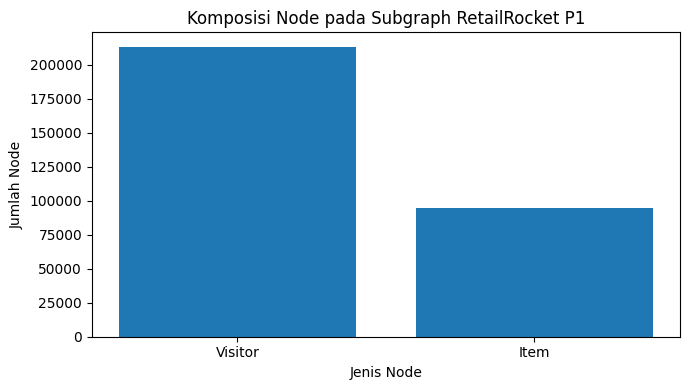

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    df_node["jenis_simpul"],
    df_node["jumlah_simpul"]
)

plt.title("Komposisi Node pada Subgraph RetailRocket P1")
plt.xlabel("Jenis Node")
plt.ylabel("Jumlah Node")

plt.tight_layout()
plt.show()

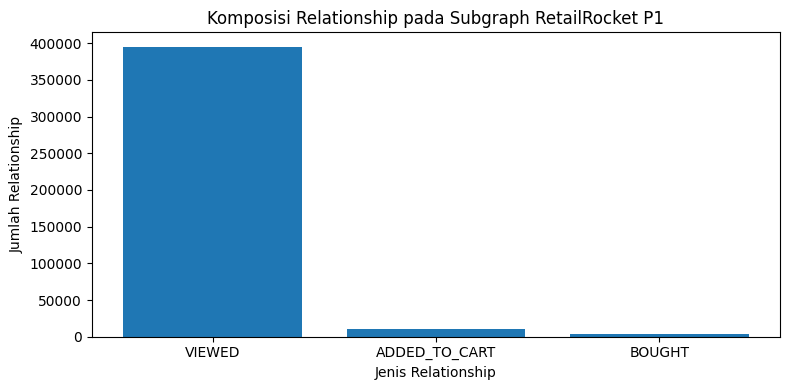

In [32]:
plt.figure(figsize=(8, 4))

plt.bar(
    df_relasi["jenis_relationship"],
    df_relasi["jumlah_relationship"]
)

plt.title("Komposisi Relationship pada Subgraph RetailRocket P1")
plt.xlabel("Jenis Relationship")
plt.ylabel("Jumlah Relationship")

plt.tight_layout()
plt.show()

### Nomor 4 

Membuat SVM User

In [45]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Mengambil pasangan User-Item dari Neo4j
query = """
MATCH (v:Visitor)-[]->(i:Item)
RETURN DISTINCT
    v.visitorId AS visitorid,
    i.itemId AS itemid
"""

with driver.session(database="neo4j") as session:
    data = session.run(query).data()

df_vsm_user = pd.DataFrame(data)

# Mengubah ID menjadi indeks matriks
user_codes, user_ids = pd.factorize(df_vsm_user["visitorid"])
item_codes, item_ids = pd.factorize(df_vsm_user["itemid"])

# Membentuk VSM biner dalam sparse matrix
vsm_user = csr_matrix(
    (
        np.ones(len(df_vsm_user), dtype=np.uint8),
        (user_codes, item_codes)
    ),
    shape=(len(user_ids), len(item_ids))
)

print("VSM User berhasil dibuat")
print("Shape:", vsm_user.shape)
print("Dimensi:", vsm_user.shape[1])

VSM User berhasil dibuat
Shape: (212988, 94576)
Dimensi: 94576


Berdasarkan hasil Vector Space Modelling (VSM), diperoleh matriks User Item dengan shape (212988, 94576). Artinya, terdapat 212.988 User dan 94.576 Item yang digunakan dalam pemodelan. Setiap baris pada matriks mewakili satu User, sedangkan setiap kolom mewakili satu Item. Nilai matriks menggunakan bentuk biner, yaitu 1 jika User pernah berinteraksi dengan Item dan 0 jika tidak terdapat interaksi yang tercatat. VSM ini dibuat untuk mengubah hubungan User Item menjadi bentuk numerik sehingga dapat digunakan dalam perhitungan similarity antar User. Selanjutnya menampilkan karakteristik VSM User sebagai berikut:

In [49]:
jumlah_user, jumlah_item = vsm_user.shape

density = vsm_user.nnz / (jumlah_user * jumlah_item)
sparsity = 1 - density

print("Karakteristik VSM User")
print("Jumlah User       :", jumlah_user)
print("Jumlah Item       :", jumlah_item)
print("Shape Matriks     :", vsm_user.shape)
print("Dimensi Vektor    :", jumlah_item)
print("Non-Zero Values   :", vsm_user.nnz)
print(f"Density           : {density * 100:.6f}%")
print(f"Sparsity          : {sparsity * 100:.6f}%")

Karakteristik VSM User
Jumlah User       : 212988
Jumlah Item       : 94576
Shape Matriks     : (212988, 94576)
Dimensi Vektor    : 94576
Non-Zero Values   : 316882
Density           : 0.001573%
Sparsity          : 99.998427%


Berdasarkan hasil perhitungan karakteristik VSM, diperoleh jumlah User sebanyak 212.988, jumlah Item sebanyak 94.576, dan jumlah nilai non-zero sebanyak 316.882. Nilai non zero menunjukkan jumlah pasangan User Item unik yang memiliki interaksi. Sementara itu, diperoleh nilai density sebesar 0,001573% dan sparsity sebesar 99,998427%. Nilai density yang sangat kecil menunjukkan bahwa hanya sedikit pasangan User dan Item yang memiliki interaksi. Sebaliknya, nilai sparsity yang sangat tinggi menunjukkan bahwa hampir seluruh elemen matriks bernilai nol. Hal itu terjadi karena jumlah User dan Item sangat banyak, tetapi setiap User hanya berinteraksi dengan sebagian kecil Item yang tersedia. Oleh karena itu, VSM disimpan menggunakan CSR Sparse Matrix agar lebih hemat memori dibandingkan menggunakan matriks biasa. Selanjutnya Melakukan plot NetworkX VSM User. Karena jumlah node sangat besar, mengvisualisasikan sampel 10 User dengan interaksi Item unik terbanyak.

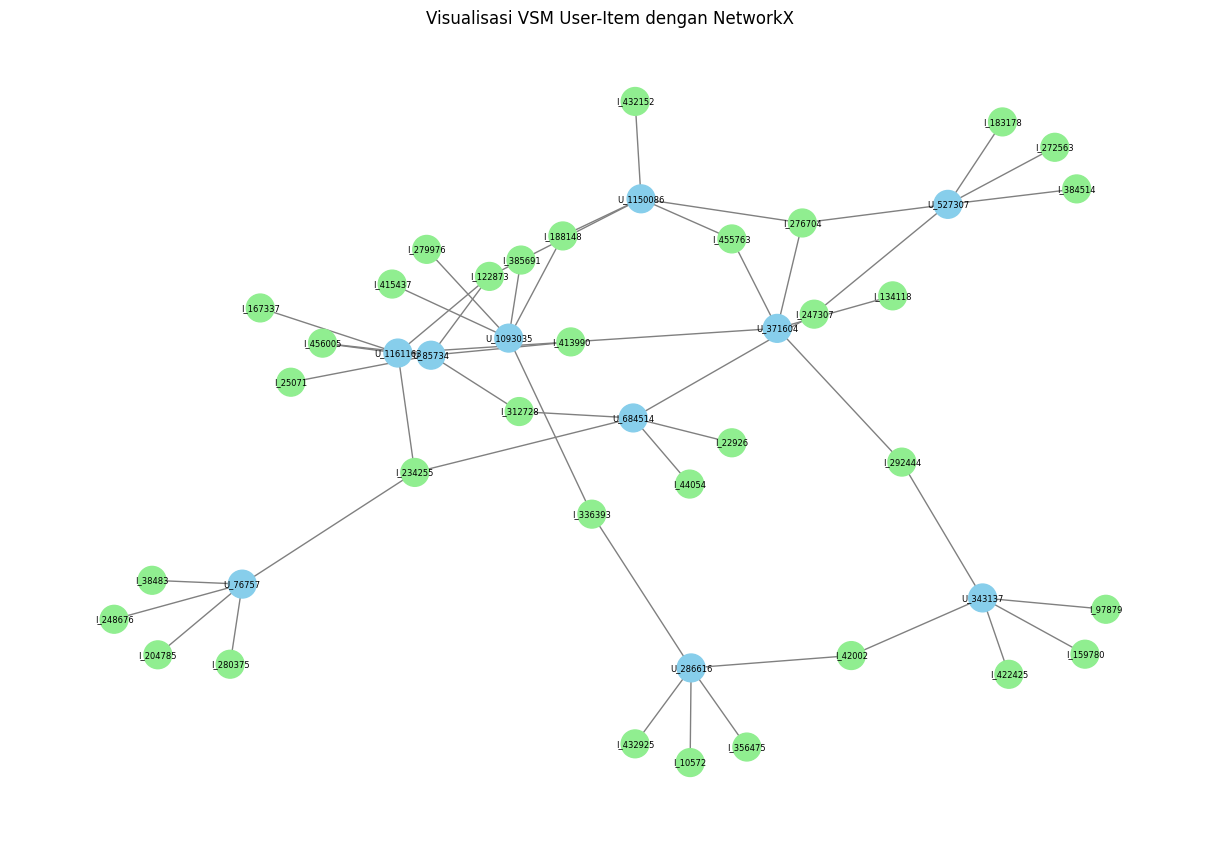

In [47]:
import networkx as nx
import matplotlib.pyplot as plt

# Memilih 10 User dengan jumlah Item unik terbanyak
top_users = (
    df_vsm_user["visitorid"]
    .value_counts()
    .head(10)
    .index
)

# Mengambil maksimal 5 Item untuk setiap User
df_plot = (
    df_vsm_user[df_vsm_user["visitorid"].isin(top_users)]
    .groupby("visitorid")
    .head(5)
)

# Membuat graf bipartit User-Item
G = nx.Graph()

for _, row in df_plot.iterrows():
    user = f"U_{row['visitorid']}"
    item = f"I_{row['itemid']}"

    G.add_node(user, tipe="User")
    G.add_node(item, tipe="Item")
    G.add_edge(user, item)

# Visualisasi
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

warna = [
    "skyblue" if G.nodes[n]["tipe"] == "User"
    else "lightgreen"
    for n in G.nodes()
]

nx.draw(
    G,
    pos,
    node_color=warna,
    with_labels=True,
    node_size=400,
    font_size=6,
    edge_color="gray"
)

plt.title("Visualisasi VSM User-Item dengan NetworkX")
plt.show()

Visualisasi dilakukan menggunakan library NetworkX untuk memperlihatkan hubungan antara User dan Item.

Pada graf yang dihasilkan:

- **Node berwarna biru** menunjukkan User.
- **Node berwarna hijau** menunjukkan Item.
- **Garis penghubung (edge)** menunjukkan adanya interaksi antara User dan Item.

Karena jumlah User dan Item sangat banyak, visualisasi hanya menggunakan sampel 10 User dengan jumlah Item unik terbanyak. Setiap User ditampilkan dengan maksimal 5 Item agar graf lebih mudah dibaca. Visualisasi ini, dapat dilihat bagaimana satu User dapat terhubung dengan beberapa Item. Apabila terdapat beberapa User yang terhubung dengan Item yang sama, hal itu menunjukkan adanya kesamaan interaksi yang dapat digunakan sebagai dasar dalam menghitung similarity antar User.

##### Kesimpulan:
Berdasarkan hasil Vector Space Modelling (VSM), diperoleh matriks User Item dengan ukuran 212.988 × 94.576 dan tingkat sparsity sebesar 99,998427%. Hasil tersebut menunjukkan bahwa matriks memiliki ukuran yang besar, tetapi sebagian besar elemennya bernilai nol karena setiap User hanya berinteraksi dengan sebagian kecil Item. Penggunaan CSR Sparse Matrix membantu menghemat penggunaan memori, sedangkan visualisasi NetworkX membantu menggambarkan pola hubungan antara User dan Item. Jadi VSM User dapat digunakan sebagai dasar untuk menganalisis kemiripan antar-User berdasarkan Item yang pernah diinteraksikan.


### Nomor 5

Pada tahap nomor 5 ini melakukan Vector Space Modelling (VSM) terhadap simpul Item untuk merepresentasikan setiap Item berdasarkan User yang pernah berinteraksi dengannya. VSM Item dibuat dengan melakukan transpose terhadap matriks VSM User yang telah dibentuk pada nomor 4. Jika pada VSM User baris mewakili User dan kolom mewakili Item, maka pada VSM Item baris mewakili Item dan kolom mewakili User.

In [50]:
vsm_item = vsm_user.T.tocsr()

print("VSM Item berhasil dibuat")
print("Shape:", vsm_item.shape)
print("Dimensi:", vsm_item.shape[1])

VSM Item berhasil dibuat
Shape: (94576, 212988)
Dimensi: 212988


Berdasarkan hasil Vector Space Modelling (VSM), diperoleh matriks Item User dengan shape (94576, 212988) yang artinya terdapat 94.576 Item dan 212.988 User yang digunakan dalam pemodelan. Setiap baris pada matriks mewakili satu Item, sedangkan setiap kolom mewakili satu User. Jadi setiap Item memiliki vektor berdimensi 212.988 yang menunjukkan interaksinya dengan User. VSM Item diperoleh dari hasil transpose VSM User pada nomor 4, sehingga jumlah User dan Item tetap sama, tetapi posisi baris dan kolomnya bertukar. Matriks ini digunakan untuk merepresentasikan Item dalam bentuk numerik sehingga dapat digunakan sebagai dasar untuk menghitung kemiripan antar Item berdasarkan User yang pernah berinteraksi dengannya. 

Setelah VSM Item terbentuk selanjutnya melakukan analisis karakteristik matriks yang meliputi jumlah Item, jumlah User, shape, dimensi vektor, jumlah nilai non-zero, density, dan sparsity. Density digunakan untuk mengetahui persentase elemen matriks yang memiliki nilai bukan nol, sedangkan sparsity menunjukkan persentase elemen matriks yang bernilai nol. Analisis ini dilakukan untuk mengetahui seberapa banyak hubungan antara Item dan User yang terdapat dalam matriks VSM.

In [51]:
jumlah_item, jumlah_user = vsm_item.shape

density_item = vsm_item.nnz / (jumlah_item * jumlah_user)
sparsity_item = 1 - density_item

print("Karakteristik VSM Item")
print("Jumlah Item       :", jumlah_item)
print("Jumlah User       :", jumlah_user)
print("Shape Matriks     :", vsm_item.shape)
print("Dimensi Vektor    :", jumlah_user)
print("Non-Zero Values   :", vsm_item.nnz)
print(f"Density           : {density_item * 100:.6f}%")
print(f"Sparsity          : {sparsity_item * 100:.6f}%")

Karakteristik VSM Item
Jumlah Item       : 94576
Jumlah User       : 212988
Shape Matriks     : (94576, 212988)
Dimensi Vektor    : 212988
Non-Zero Values   : 316882
Density           : 0.001573%
Sparsity          : 99.998427%


Berdasarkan hasil karakteristik VSM Item, hasilnya jumlah Item sebanyak 94.576, jumlah User sebanyak 212.988, dan jumlah nilai non-zero sebanyak 316.882.
Jumlah nilai non zero menunjukkan banyaknya pasangan Item User unik yang memiliki interaksi. Nilai ini sama dengan VSM User karena VSM Item dibuat menggunakan transpose, sehingga hanya posisi baris dan kolom yang berubah. Selain itu, diperoleh nilai density sebesar 0,001573% dan sparsity sebesar 99,998427%. Nilai density yang sangat kecil menunjukkan bahwa hanya sedikit pasangan Item dan User yang memiliki interaksi. Sebaliknya, nilai sparsity yang sangat tinggi menunjukkan bahwa hampir seluruh elemen matriks bernilai nol. Ini terjadi karena jumlah Item dan User sangat banyak, tetapi setiap Item hanya diinteraksikan oleh sebagian kecil User yang tersedia. Jadi VSM Item disimpan menggunakan CSR Sparse Matrix agar penggunaan memori lebih hemat dibandingkan menyimpan matriks dalam bentuk biasa.

Tahap selanjutnya melakukan visualisasi hubungan antara Item dan User menggunakan library NetworkX. Karena jumlah Item dan User sangat banyak, visualisasi hanya menggunakan sampel 10 Item dengan jumlah User unik terbanyak. Selanjutnya, diambil maksimal 5 User untuk setiap Item agar graf yang dihasilkan tidak terlalu padat dan lebih mudah dibaca. Graf dibentuk sebagai graf bipartit yang terdiri dari dua jenis node, yaitu Item dan User. Node Item ditampilkan dengan warna hijau, sedangkan node User ditampilkan dengan warna biru.

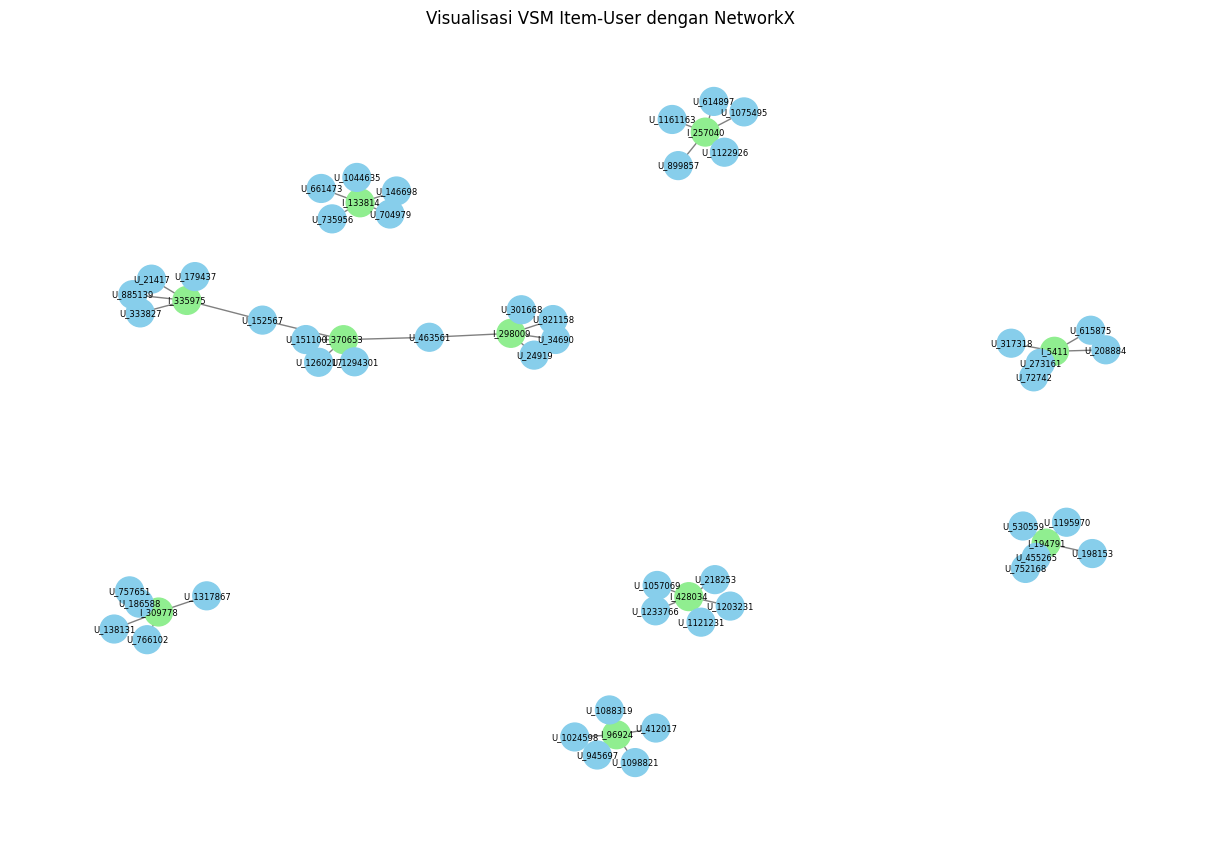

In [52]:
import networkx as nx
import matplotlib.pyplot as plt

top_items = (
    df_vsm_user["itemid"]
    .value_counts()
    .head(10)
    .index
)

df_plot_item = (
    df_vsm_user[df_vsm_user["itemid"].isin(top_items)]
    .groupby("itemid")
    .head(5)
)

G_item = nx.Graph()

for _, row in df_plot_item.iterrows():
    item = f"I_{row['itemid']}"
    user = f"U_{row['visitorid']}"

    G_item.add_node(item, tipe="Item")
    G_item.add_node(user, tipe="User")
    G_item.add_edge(item, user)

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G_item, seed=42)

warna_item = [
    "lightgreen" if G_item.nodes[n]["tipe"] == "Item"
    else "skyblue"
    for n in G_item.nodes()
]

nx.draw(
    G_item,
    pos,
    node_color=warna_item,
    with_labels=True,
    node_size=400,
    font_size=6,
    edge_color="gray"
)

plt.title("Visualisasi VSM Item-User dengan NetworkX")
plt.show()

Dari graf yang dihasilkan, terlihat bahwa satu Item dapat terhubung dengan beberapa User. Selain itu, terdapat beberapa Item yang memiliki hubungan dengan User yang sama. Hal ini menunjukkan adanya kesamaan pola interaksi antar Item. Pada visualisasi juga terlihat beberapa kelompok node yang terpisah. Hal ini menunjukkan bahwa pada sampel yang ditampilkan, tidak semua Item memiliki User yang sama atau saling terhubung melalui User. Kesamaan interaksi tersebut dapat digunakan sebagai dasar untuk menghitung similarity antar Item dalam sistem rekomendasi.

##### Kesimpulan:
Berdasarkan hasil Vector Space Modelling (VSM) Item, diperoleh matriks Item–User dengan ukuran 94.576 × 212.988 dan jumlah nilai non-zero sebanyak 316.882.
Matriks tersebut memiliki nilai density sebesar 0,001573% dan sparsity sebesar 99,998427%. Hal ini menunjukkan bahwa matriks memiliki dimensi yang sangat besar, tetapi sebagian besar elemennya bernilai nol karena setiap Item hanya diinteraksikan oleh sebagian kecil User. Penggunaan CSR Sparse Matrix membantu menghemat penggunaan memori, sedangkan visualisasi NetworkX membantu memperlihatkan pola hubungan antara Item dan User. Jadi VSM Item dapat digunakan sebagai dasar untuk menghitung kemiripan antar-Item berdasarkan User yang pernah berinteraksi dengannya.

### Nomor 6

Pada nomor 6 ini melakukan perbandingan karakteristik antara VSM User dan VSM Item berdasarkan hasil pemodelan pada nomor 4 dan 5. Perbandingan dilakukan untuk mengetahui perbedaan jumlah objek, dimensi vektor, shape matriks, jumlah nilai non-zero, density, dan sparsity. VSM User merepresentasikan setiap User berdasarkan Item yang pernah diinteraksikan, sedangkan VSM Item merepresentasikan setiap Item berdasarkan User yang pernah berinteraksi dengannya.
Hasil perbandingan ini digunakan sebagai dasar untuk menentukan proyeksi yang lebih efisien dalam perhitungan similarity.

In [53]:
import pandas as pd

perbandingan_vsm = pd.DataFrame({
    "Karakteristik": [
        "Jumlah objek",
        "Dimensi vektor",
        "Shape matriks",
        "Non-Zero Values",
        "Density (%)",
        "Sparsity (%)"
    ],
    "VSM User": [
        vsm_user.shape[0],
        vsm_user.shape[1],
        str(vsm_user.shape),
        vsm_user.nnz,
        round(vsm_user.nnz / (vsm_user.shape[0] * vsm_user.shape[1]) * 100, 6),
        round((1 - vsm_user.nnz / (vsm_user.shape[0] * vsm_user.shape[1])) * 100, 6)
    ],
    "VSM Item": [
        vsm_item.shape[0],
        vsm_item.shape[1],
        str(vsm_item.shape),
        vsm_item.nnz,
        round(vsm_item.nnz / (vsm_item.shape[0] * vsm_item.shape[1]) * 100, 6),
        round((1 - vsm_item.nnz / (vsm_item.shape[0] * vsm_item.shape[1])) * 100, 6)
    ]
})

display(perbandingan_vsm)

,Karakteristik,VSM User,VSM Item
0,Jumlah objek,212988,94576
1,Dimensi vektor,94576,212988
2,Shape matriks,"(212988, 94576)","(94576, 212988)"
3,Non-Zero Values,316882,316882
4,Density (%),0.001573,0.001573
5,Sparsity (%),99.998427,99.998427


Berdasarkan hasil perbandingan karakteristik VSM User dan VSM Item, terlihat bahwa VSM User memiliki 212.988 objek dengan dimensi vektor sebanyak 94.576, sedangkan VSM Item memiliki 94.576 objek dengan dimensi vektor sebanyak 212.988. Perbedaan tersebut terjadi karena VSM Item merupakan hasil transpose dari VSM User, sehingga posisi baris dan kolom pada matriks saling bertukar. Meskipun memiliki shape dan dimensi vektor yang berbeda, kedua matriks memiliki jumlah nilai non-zero yang sama, yaitu 316.882, dengan density sebesar 0,001573% dan sparsity sebesar 99,998427%. Hasil tersebut menunjukkan bahwa kedua matriks memiliki tingkat kepadatan yang sama dan sebagian besar elemennya bernilai nol. VSM Item memiliki jumlah objek yang lebih sedikit dibandingkan VSM User. Perbedaan jumlah objek ini menjadi salah satu pertimbangan dalam menentukan proyeksi yang lebih efisien untuk perhitungan similarity.

Tahap selanjutnya melakukan perbandingan jumlah kemungkinan pasangan similarity antara perkiraan User–User dan Item–Item. User–User digunakan untuk menghitung kemiripan antar-User berdasarkan Item yang pernah diinteraksikan. Sementara itu, perkiraan Item–Item digunakan untuk menghitung kemiripan antar-Item berdasarkan User yang pernah berinteraksi dengannya. Untuk mengetahui perkiraan yang lebih efisien, dihitung jumlah kemungkinan pasangan yang dapat terbentuk dari masing-masing perkiraan. 

In [55]:
jumlah_user = vsm_user.shape[0]
jumlah_item = vsm_item.shape[0]

pasangan_user = jumlah_user * (jumlah_user - 1) // 2
pasangan_item = jumlah_item * (jumlah_item - 1) // 2

print("Perbandingan Jumlah Pasangan Similarity")
print(f"User-User : {pasangan_user:,}")
print(f"Item-Item : {pasangan_item:,}")

print(
    f"\nJumlah pasangan User-User sekitar "
    f"{pasangan_user / pasangan_item:.2f} kali "
    f"lebih banyak dibandingkan Item-Item."
)

Perbandingan Jumlah Pasangan Similarity
User-User : 22,681,837,578
Item-Item : 4,472,262,600

Jumlah pasangan User-User sekitar 5.07 kali lebih banyak dibandingkan Item-Item.


Berdasarkan hasil perhitungan jumlah kemungkinan pasangan similarity, diperoleh sebanyak 22.681.837.578 pasangan User–User dan 4.472.262.600 pasangan Item–Item. Hasil tersebut menunjukkan bahwa jumlah kemungkinan pasangan pada perkiraan User–User sekitar 5,07 kali lebih banyak dibandingkan perkiraan Item–Item. Perbedaan ini terjadi karena jumlah User pada dataset lebih banyak dibandingkan jumlah Item, sehingga kemungkinan pasangan User–User yang terbentuk juga lebih besar. Oleh karena itu perkiraan Item–Item lebih efisien dari segi jumlah kemungkinan pasangan similarity karena memiliki lebih sedikit objek yang perlu dibandingkan. Tapi hasil ini hanya menunjukkan perbandingan jumlah kemungkinan pasangan, bukan hasil pengukuran waktu komputasi secara langsung. Waktu perhitungan sebenarnya juga dapat dipengaruhi oleh dimensi vektor, jumlah interaksi, dan metode perhitungan similarity yang digunakan.

##### Kesimpulan:

Berdasarkan hasil perbandingan VSM User dan VSM Item, dapat disimpulkan bahwa prediksi Item–Item lebih efisien dari segi jumlah kemungkinan pasangan similarity. Hal ini disebabkan oleh jumlah Item yang lebih sedikit, yaitu 94.576 Item, dibandingkan jumlah User yang mencapai 212.988 User. Akibatnya, jumlah kemungkinan pasangan Item–Item hanya sekitar 4,47 miliar, sedangkan pasangan User–User mencapai 22,68 miliar. Dari segi efektivitas, kedua prediksi memiliki kegunaan yang berbeda. Proyeksi User–User digunakan untuk mencari User yang memiliki pola interaksi serupa, sedangkan prediksi Item–Item digunakan untuk mencari Item yang memiliki kesamaan berdasarkan User yang pernah berinteraksi dengannya. Dalam sistem rekomendasi produk, prediksi Item–Item dapat digunakan untuk merekomendasikan produk yang mirip dengan produk yang sebelumnya pernah diinteraksikan oleh User. Meskipun efektivitas kedua prediksi belum dapat dipastikan hanya berdasarkan ukuran matriks dan jumlah pasangan similarity. Untuk mengetahui prediksi yang menghasilkan rekomendasi lebih baik, diperlukan evaluasi menggunakan data testing. Jadi berdasarkan hasil eksplorasi pada nomor 4 dan 5, prediksi Item–Item (simpul yang diasumsikan sebagai Item) dipilih sebagai prediksi yang lebih efisien untuk perhitungan similarity secara menyeluruh karena memiliki jumlah kemungkinan pasangan yang lebih sedikit dibandingkan prediksi User–User.

### Nomor 7

Pada nomor 7 melakukan pemilihan Item acuan yang akan digunakan untuk menghitung similarity antar-Item. Berdasarkan hasil analisis nomor 6, dipilih proyeksi Item–Item (simpul yang diasumsikan sebagai Item) karena memiliki jumlah kemungkinan pasangan similarity yang lebih sedikit dibandingkan proyeksi User–User (simpul yang diasumsikan sebagai User). Item acuan ditentukan berdasarkan Item yang memiliki jumlah User unik terbanyak pada data interaksi yang digunakan untuk membentuk VSM Item. Pemilihan ini dilakukan agar Item acuan memiliki cukup banyak interaksi untuk dibandingkan dengan Item lainnya.

In [56]:
item_acuan = df_vsm_user["itemid"].value_counts().idxmax()

print("Item acuan:", item_acuan)
print(
    "Jumlah User yang berinteraksi:",
    df_vsm_user["itemid"].value_counts().max()
)

Item acuan: 5411
Jumlah User yang berinteraksi: 1012


Hasil pemilihan Item acuan diperoleh Item 5411 dengan jumlah User yang pernah berinteraksi sebanyak 1.012 User. Item tersebut dipilih karena memiliki jumlah User unik terbanyak pada data interaksi yang digunakan. Dengan banyaknya User yang pernah berinteraksi, Item 5411 dapat digunakan sebagai acuan untuk mencari Item lain yang memiliki pola interaksi yang sama.

Selanjutnya melakukan perhitungan similarity menggunakan metode Cosine Similarity berdasarkan VSM Item yang telah dibuat pada nomor 5. Perhitungan dilakukan dengan membandingkan vektor Item 5411 terhadap seluruh vektor Item lainnya. Nilai Cosine Similarity menunjukkan tingkat kemiripan pola interaksi antar-Item berdasarkan User yang pernah berinteraksi dengannya. Karena VSM menggunakan nilai biner non negatif, nilai similarity berada pada rentang 0 sampai 1. Semakin mendekati 1, semakin tinggi tingkat kemiripan antar-Item.

In [58]:
%pip install scikit-learn

  Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl.metadata (11 kB)
Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl (8.9 MB)

   ---------- ----------------------------- 1/4 [cloudpickle]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [job


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Mencari posisi Item acuan dalam VSM Item
idx_acuan = np.where(item_ids == item_acuan)[0][0]

# Menghitung similarity Item acuan dengan seluruh Item
similarity_scores = cosine_similarity(
    vsm_item[idx_acuan],
    vsm_item
).ravel()

# Membuat DataFrame hasil similarity
df_similarity = pd.DataFrame({
    "itemid": item_ids,
    "similarity": similarity_scores
})

# Menghapus Item acuan dari hasil
df_similarity = df_similarity[
    df_similarity["itemid"] != item_acuan
]

# Mengambil 5 Item dengan similarity tertinggi
top5_similarity = (
    df_similarity
    .sort_values("similarity", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("Item acuan:", item_acuan)
display(top5_similarity)

Item acuan: 5411


,itemid,similarity
0,33030,0.194950
1,33956,0.105435
2,358234,0.102665
3,375492,0.080496
4,89143,0.075612


Hasil perhitungan Cosine Similarity diperoleh lima Item dengan nilai similarity tertinggi terhadap Item acuan 5411. Item dengan nilai similarity tertinggi adalah Item 33030 dengan skor 0,194950, lalu Item 33956 sebesar 0,105435, Item 358234 sebesar 0,102665, Item 375492 sebesar 0,080496, dan Item 89143 sebesar 0,075612. Dari hasil tersebut, Item 33030 memiliki pola interaksi User yang paling mirip dengan Item 5411 dibandingkan Item lainnya. Tapi, seluruh nilai similarity yang diperoleh masih relatif rendah karena berada di bawah 0,2. Hal ini menunjukkan bahwa tingkat kemiripan pola interaksi User antara Item acuan dan kelima Item tersebut masih terbatas. Hasil perhitungan ini selanjutnya disimpan ke dalam graf Neo4j menggunakan relationship SIMILAR_TO.

### Nomor 7(b) 

Setelah memperoleh lima Item dengan nilai similarity tertinggi, hasil perhitungan tersebut disimpan kembali ke database Neo4j. Penyimpanan dilakukan dengan membuat relationship SIMILAR_TO antara Item acuan 5411 dan lima Item hasil perhitungan similarity. Setiap relationship memiliki properti score yang digunakan untuk menyimpan nilai Cosine Similarity. Pada pengerjaan ini, nomor 7(b) dilakukan terlebih dahulu agar relationship similarity tersedia di Neo4j sebelum ditampilkan menggunakan query Cypher pada nomor 7(a).

In [61]:
# Menyiapkan data untuk disimpan ke Neo4j
data_similarity = [
    {
        "itemid": int(row["itemid"]),
        "score": float(row["similarity"])
    }
    for _, row in top5_similarity.iterrows()
]

query_simpan = """
MATCH (a:Item {itemId: $item_acuan})
UNWIND $data_similarity AS row
MATCH (b:Item {itemId: row.itemid})

MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = row.score

RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       r.score AS similarity
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        query_simpan,
        item_acuan=int(item_acuan),
        data_similarity=data_similarity
    )

    hasil_simpan = [record.data() for record in result]

df_hasil_simpan = pd.DataFrame(hasil_simpan)

display(df_hasil_simpan)

,item_acuan,item_mirip,similarity
0,5411,33030,0.194950
1,5411,33956,0.105435
2,5411,358234,0.102665
3,5411,375492,0.080496
4,5411,89143,0.075612


Berdasarkan hasil penyimpanan, lima nilai Cosine Similarity berhasil dituliskan ke dalam database Neo4j. Item 5411 digunakan sebagai node acuan yang dihubungkan dengan lima Item lainnya menggunakan relationship SIMILAR_TO. Setiap relationship memiliki properti score yang berisi nilai similarity hasil perhitungan menggunakan Python. Perintah MERGE digunakan agar hubungan dengan pasangan Item yang sama tidak dibuat kembali apabila relationship tersebut sudah tersedia. Sementara itu, perintah SET digunakan untuk menyimpan atau memperbarui nilai similarity. Hasil perhitungan similarity tidak hanya tersedia dalam DataFrame Python, tetapi juga tersimpan sebagai relationship pada graf Neo4j.

### Nomor 7(a)

Setelah nilai similarity berhasil disimpan pada graf Neo4j, dilakukan query Cypher untuk mendapatkan lima Item dengan nilai similarity tertinggi terhadap Item acuan 5411. Query dilakukan dengan mencari relationship SIMILAR_TO yang menghubungkan Item acuan dengan Item lainnya. Hasil query kemudian diurutkan berdasarkan nilai similarity dari yang tertinggi hingga terendah dan dibatasi sebanyak lima record.

In [62]:
query_top5 = """
MATCH (a:Item {itemId: $item_acuan})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_mirip,
    r.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        query_top5,
        item_acuan=int(item_acuan)
    )

    hasil_top5 = [record.data() for record in result]

df_top5 = pd.DataFrame(hasil_top5)

print("5 Item dengan similarity tertinggi:")
display(df_top5)

5 Item dengan similarity tertinggi:


,item_acuan,item_mirip,similarity
0,5411,33030,0.194950
1,5411,33956,0.105435
2,5411,358234,0.102665
3,5411,375492,0.080496
4,5411,89143,0.075612


Hasil query Cypher diperoleh lima Item dengan nilai similarity tertinggi terhadap Item acuan 5411. Item 33030 memiliki nilai similarity tertinggi sebesar 0,194950, sedangkan Item 89143 memiliki nilai similarity terendah dari lima hasil tersebut, yaitu sebesar 0,075612. Hasil query Neo4j menunjukkan nilai similarity yang sama dengan hasil perhitungan Python sebelumnya. Hal ini menunjukkan bahwa nilai similarity yang dihitung menggunakan Python berhasil disimpan pada relationship SIMILAR_TO dan dapat ditampilkan kembali menggunakan Cypher.

In [63]:
query_graf = """
MATCH (a:Item {itemId: $item_acuan})-[r:SIMILAR_TO]->(b:Item)
RETURN a, r, b
ORDER BY r.score DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        query_graf,
        item_acuan=int(item_acuan)
    )

    print("Jumlah relationship similarity:", len(result.data()))

Jumlah relationship similarity: 5


Pada tahap selanjutnya melakukan visualisasi hasil similarity untuk memperlihatkan hubungan antara Item acuan dan lima Item yang memiliki nilai similarity tertinggi. Visualisasi dilakukan menggunakan Neo4j dengan menampilkan node Item beserta relationship SIMILAR_TO yang menghubungkannya.

Berdasarkan hasil visualisasi Neo4j (file Graf no 7a), diperoleh graf yang terdiri dari 6 node Item dan 5 relationship SIMILAR_TO. Pada graf tersebut, Item 5411 menjadi node pusat yang terhubung dengan lima Item lainnya, yaitu Item 33030, 33956, 358234, 375492, dan 89143. Relationship SIMILAR_TO menunjukkan adanya kemiripan pola interaksi User antara Item acuan dan Item lainnya. Nilai similarity disimpan pada properti score di setiap relationship. Semakin tinggi nilainya, semakin mirip pola interaksi User antara kedua Item tersebut. Visualisasi tersebut menunjukkan bahwa hasil perhitungan similarity menggunakan Python berhasil direpresentasikan kembali dalam bentuk graf Neo4j.

### Kesimpulan

Berdasarkan hasil perhitungan similarity menggunakan metode Cosine Similarity, diperoleh lima Item dengan nilai similarity tertinggi terhadap Item acuan 5411. Item yang memiliki similarity tertinggi adalah Item 33030 dengan nilai sebesar 0,194950, sedangkan Item dengan similarity terendah dari lima hasil tersebut adalah Item 89143 dengan nilai sebesar 0,075612. Hasil perhitungan similarity menggunakan Python kemudian berhasil disimpan ke database Neo4j menggunakan relationship SIMILAR_TO dengan properti score.

Pada pengerjaan ini, nomor 7(b) dilakukan terlebih dahulu sebelum nomor 7(a). Hal ini karena nilai similarity awalnya dihitung menggunakan Python dan belum tersimpan sebagai relationship pada graf Neo4j. Oleh karena itu, hasil perhitungan similarity perlu disimpan terlebih dahulu melalui nomor 7(b) agar dapat diambil dan ditampilkan menggunakan query Cypher pada nomor 7(a). Setelah nilai similarity berhasil disimpan, query Cypher pada nomor 7(a) dapat menampilkan kembali lima Item dengan nilai similarity tertinggi yang sesuai dengan hasil perhitungan Python. Visualisasi Neo4j juga menunjukkan bahwa Item 5411 terhubung dengan lima Item lainnya melalui relationship SIMILAR_TO.

### Nomor 8

Pada nomor 8 melakukan visualisasi graf untuk membandingkan kondisi sebelum dan sesudah perhitungan Cosine Similarity. Visualisasi menggunakan Item 5411 sebagai item acuan dan lima Item dengan similarity tertinggi yang telah diperoleh pada nomor 7. Sebelum perhitungan similarity, hubungan antar-Item belum direpresentasikan menggunakan relationship SIMILAR_TO. Setelah perhitungan similarity, hubungan kemiripan antar-Item direpresentasikan menggunakan relationship SIMILAR_TO beserta nilai similarity-nya. Karena relationship SIMILAR_TO sudah dibuat pada nomor 7 jadi tidak perlu menghapusnya. Untuk memperlihatkan kondisi sebelum perhitungan, kita cukup mengambil enam Item yang sama tanpa menampilkan relationship SIMILAR_TO.

C:\Users\Yuviana\AppData\Local\Temp\ipykernel_34388\520089987.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


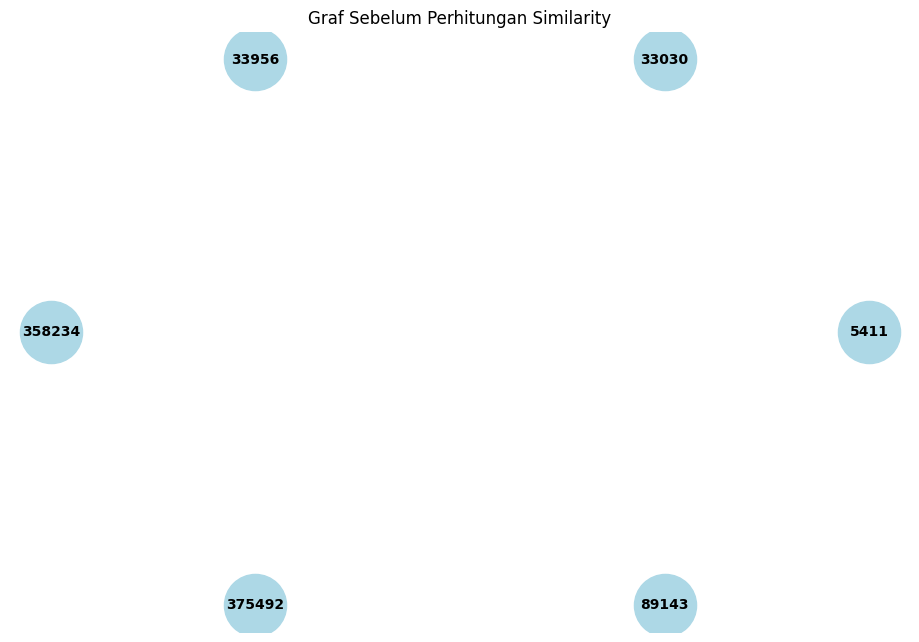

In [64]:
import matplotlib.pyplot as plt
import networkx as nx

# Mengambil Item acuan dan 5 Item hasil similarity
daftar_item = [int(item_acuan)] + top5_similarity["itemid"].astype(int).tolist()

# Cypher SQL sebelum similarity
query_sebelum = """
MATCH (i:Item)
WHERE i.itemId IN $daftar_item
RETURN i.itemId AS itemid
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        query_sebelum,
        daftar_item=daftar_item
    )

    data_sebelum = [record.data() for record in result]

# Membuat graf
G_sebelum = nx.Graph()

for row in data_sebelum:
    G_sebelum.add_node(row["itemid"])

# Visualisasi
plt.figure(figsize=(9, 6))

pos = nx.circular_layout(G_sebelum)

nx.draw(
    G_sebelum,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=2000,
    font_size=10,
    font_weight="bold"
)

plt.title("Graf Sebelum Perhitungan Similarity")

plt.tight_layout()
plt.show()

Sebelum perhitungan similarity, keenam Item ditampilkan sebagai node yang belum memiliki relationship SIMILAR_TO di antara Item acuan dan lima Item pembanding. Pada tahap ini, graf hanya memperlihatkan node Item tanpa hubungan kemiripan antar-Item. Selanjutnya, kita menampilkan relationship SIMILAR_TO yang sudah disimpan pada nomor 7.

C:\Users\Yuviana\AppData\Local\Temp\ipykernel_34388\2748011705.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


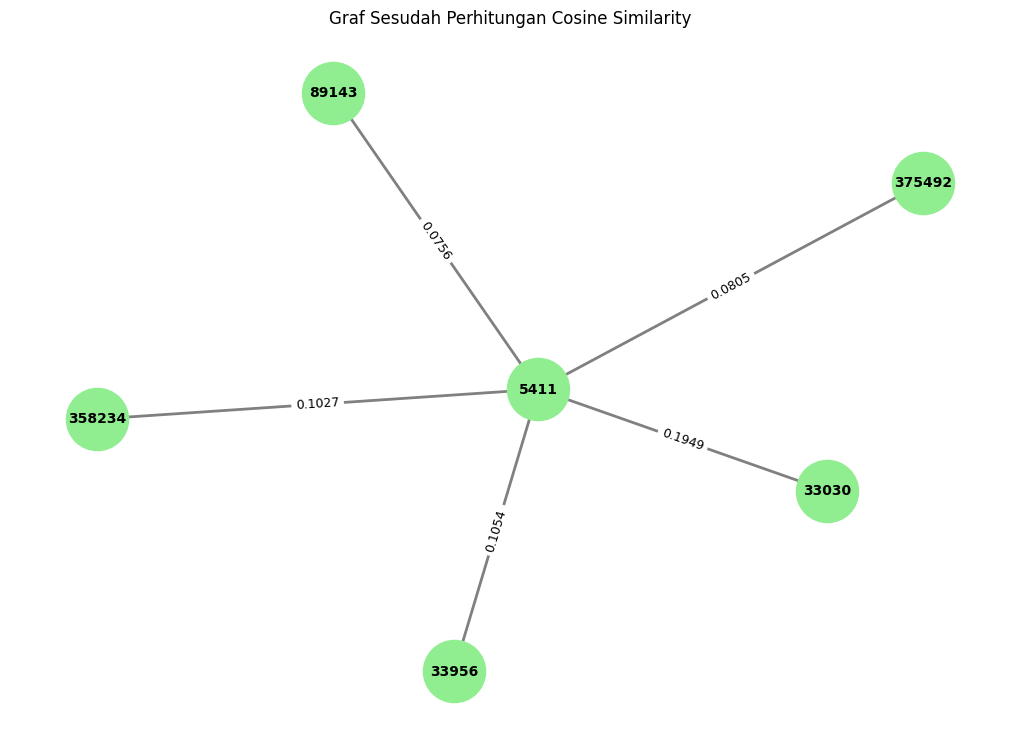

In [65]:
# Cypher SQL sesudah similarity
query_sesudah = """
MATCH (a:Item {itemId: $item_acuan})-[r:SIMILAR_TO]->(b:Item)

RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_mirip,
    r.score AS similarity

ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        query_sesudah,
        item_acuan=int(item_acuan)
    )

    data_sesudah = [record.data() for record in result]

# Membuat graf
G_sesudah = nx.Graph()

for row in data_sesudah:
    G_sesudah.add_edge(
        row["item_acuan"],
        row["item_mirip"],
        weight=row["similarity"]
    )

# Visualisasi
plt.figure(figsize=(10, 7))

pos = nx.spring_layout(
    G_sesudah,
    seed=42
)

nx.draw(
    G_sesudah,
    pos,
    with_labels=True,
    node_color="lightgreen",
    node_size=2000,
    font_size=10,
    font_weight="bold",
    edge_color="gray",
    width=2
)

# Menampilkan nilai similarity
edge_labels = {
    (u, v): f"{d['weight']:.4f}"
    for u, v, d in G_sesudah.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_sesudah,
    pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Graf Sesudah Perhitungan Cosine Similarity")

plt.tight_layout()
plt.show()

Setelah dilakukan perhitungan Cosine Similarity, terbentuk lima relationship SIMILAR_TO yang menghubungkan Item 5411 dengan lima Item yang memiliki similarity tertinggi. Setiap relationship memiliki properti score yang menunjukkan tingkat kemiripan berdasarkan pola interaksi User terhadap Item. Item 33030 memiliki nilai similarity tertinggi sebesar 0,194950, sedangkan Item 89143 memiliki nilai similarity terendah di antara lima Item teratas, yaitu 0,075612.

### Kesimpulan

Berdasarkan hasil visualisasi, terlihat perbedaan gambar visualisasi graf sebelum dan sesudah perhitungan similarity. Sebelum perhitungan similarity, hubungan kemiripan antar-Item belum direpresentasikan pada graf yang ditampilkan. Setelah perhitungan similarity, terbentuk relationship SIMILAR_TO yang menghubungkan Item acuan dengan lima Item paling mirip. Penambahan relationship tersebut memungkinkan graf RetailRocket merepresentasikan kemiripan antar-Item berdasarkan pola interaksi User, sehingga dapat digunakan sebagai dasar pengembangan sistem rekomendasi produk.

# Soal UTS 2.2 Analytics

### Nomor 1

Pada nomor 1 ini melakukan persiapan data untuk membangun sistem rekomendasi menggunakan algoritma K-Nearest Neighbors (KNN). Data yang digunakan berasal dari periode training (P1), yaitu 1–20 Juni 2015. Data tersebut digunakan untuk membentuk Vector Space Model (VSM) User–Item dalam bentuk matriks biner.
Setiap baris pada matriks merepresentasikan User, sedangkan setiap kolom merepresentasikan Item. Nilai 1 menunjukkan bahwa User pernah berinteraksi dengan Item, sedangkan nilai 0 menunjukkan bahwa tidak terdapat interaksi.  Matriks dibentuk menggunakan sparse matrix untuk menghemat penggunaan memori karena sebagian besar pasangan User–Item tidak memiliki interaksi. VSM khusus training digunakan agar data testing (P2) tidak ikut memengaruhi perhitungan similarity dan proses rekomendasi.

In [ ]:
# PERSIAPAN DATA KNN

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Mengambil pasangan User-Item dari P1
df_knn_train = (
    df_train[["visitorid", "itemid"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

# Mengurutkan data
df_knn_train = (
    df_knn_train
    .sort_values(["visitorid", "itemid"])
    .reset_index(drop=True)
)

# Membentuk indeks User dan Item
user_codes, user_ids_knn = pd.factorize(
    df_knn_train["visitorid"],
    sort=True
)

item_codes, item_ids_knn = pd.factorize(
    df_knn_train["itemid"],
    sort=True
)

# Membentuk VSM User-Item
vsm_user_knn = csr_matrix(
    (
        np.ones(len(df_knn_train), dtype=np.float64),
        (user_codes, item_codes)
    ),
    shape=(len(user_ids_knn), len(item_ids_knn))
)

# Membuat mapping User ke indeks VSM
user_to_idx = {
    int(uid): idx
    for idx, uid in enumerate(user_ids_knn)
}

print("PERSIAPAN DATA BERHASIL")
print("Shape VSM :", vsm_user_knn.shape)
print("Jumlah User :", len(user_ids_knn))
print("Jumlah Item :", len(item_ids_knn))
print("Jumlah Mapping User :", len(user_to_idx))

PERSIAPAN DATA BERHASIL
Shape VSM : (212988, 94576)
Jumlah User : 212988
Jumlah Item : 94576
Jumlah Mapping User : 212988


Berdasarkan hasil persiapan data, diperoleh VSM User–Item dengan ukuran 212.988 × 94.576, yang menunjukkan bahwa terdapat 212.988 User dan 94.576 Item pada data training (P1). Setiap User direpresentasikan berdasarkan Item yang pernah diinteraksikan, sehingga matriks tersebut dapat digunakan untuk menghitung tingkat kemiripan antar-User. Selain itu, diperoleh sebanyak 212.988 mapping User yang digunakan untuk menghubungkan ID User dengan posisi baris pada matriks VSM. Lalu data training telah berhasil dipersiapkan dan dapat digunakan untuk proses pemilihan User serta perhitungan KNN.

Tahap selanjtnya melakukan pemilihan satu User secara acak yang akan digunakan sebagai acuan dalam proses rekomendasi KNN. Pemilihan dilakukan menggunakan metode random sampling dengan random seed = 42 agar hasil pengacakan dapat direproduksi. User yang menjadi kandidat harus terdapat pada data training (P1) dan testing (P2), sehingga hasil rekomendasi nantinya dapat dievaluasi menggunakan data testing. Lalu melakukan penyaringan berdasarkan data training untuk memastikan bahwa setiap User yang memenuhi kriteria memiliki minimal lima tetangga dengan nilai Cosine Similarity positif dan minimal lima kandidat Item yang dapat direkomendasikan. Setelah seluruh User yang memenuhi kriteria diperoleh, dipilih satu User secara acak menggunakan random seed yang telah ditentukan.

In [76]:
# PEMILIHAN USER SECARA ACAK DAN REPRODUCIBLE

random_state = 42
rng = np.random.default_rng(random_state)

# User pada P1 dan P2
user_train = set(
    df_train["visitorid"].dropna().astype(int).unique()
)

user_test = set(
    df_test["visitorid"].dropna().astype(int).unique()
)

# User yang terdapat pada kedua periode
user_kandidat = sorted(
    user_train.intersection(user_test)
)

# Fungsi untuk menghitung KNN dan kandidat rekomendasi
def hitung_knn_rekomendasi(uid, k=5):

    idx_user = user_to_idx[int(uid)]

    # Menghitung Cosine Similarity
    similarity = cosine_similarity(
        vsm_user_knn[idx_user],
        vsm_user_knn
    ).ravel()

    # Menghapus User itu sendiri
    similarity[idx_user] = -1

    # Membuat DataFrame similarity
    df_similarity = pd.DataFrame({
        "visitorid": user_ids_knn,
        "similarity": similarity
    })

    # Mengambil k tetangga dengan similarity positif
    top_knn = (
        df_similarity[df_similarity["similarity"] > 0]
        .sort_values(
            ["similarity", "visitorid"],
            ascending=[False, True]
        )
        .head(k)
        .reset_index(drop=True)
    )

    if len(top_knn) < k:
        return None, None

    # Item yang sudah diinteraksikan User
    item_user = set(
        df_knn_train.loc[
            df_knn_train["visitorid"] == uid,
            "itemid"
        ]
    )

    # Mengambil Item dari k tetangga
    df_tetangga = df_knn_train[
        df_knn_train["visitorid"].isin(
            top_knn["visitorid"]
        )
    ].copy()

    # Menambahkan similarity tetangga
    df_tetangga = df_tetangga.merge(
        top_knn,
        on="visitorid",
        how="left"
    )

    # Menghapus Item yang sudah diinteraksikan
    df_kandidat = df_tetangga[
        ~df_tetangga["itemid"].isin(item_user)
    ].copy()

    # Menghitung skor rekomendasi
    df_rekomendasi = (
        df_kandidat
        .groupby("itemid")
        .agg(
            skor_rekomendasi=("similarity", "sum"),
            jumlah_tetangga=("visitorid", "nunique")
        )
        .reset_index()
        .sort_values(
            ["skor_rekomendasi", "jumlah_tetangga", "itemid"],
            ascending=[False, False, True]
        )
        .reset_index(drop=True)
    )

    return top_knn, df_rekomendasi

# MENENTUKAN USER YANG MEMENUHI KRITERIA

user_layak = []

for uid in user_kandidat:

    if int(uid) not in user_to_idx:
        continue

    top_knn, df_rekomendasi = hitung_knn_rekomendasi(
        uid,
        k=5
    )

    if top_knn is None:
        continue

    # Minimal 5 kandidat Item
    if len(df_rekomendasi) >= 5:
        user_layak.append(int(uid))

# MEMILIH SATU USER SECARA ACAK

if len(user_layak) == 0:
    raise ValueError(
        "Tidak ditemukan User yang memenuhi kriteria."
    )

user_terpilih = int(
    rng.choice(sorted(user_layak))
)

print("PEMILIHAN USER")
print("Random State :", random_state)
print("Jumlah User Kandidat :", len(user_kandidat))
print("Jumlah User Layak :", len(user_layak))
print("User Terpilih :", user_terpilih)

PEMILIHAN USER
Random State : 42
Jumlah User Kandidat : 4611
Jumlah User Layak : 344
User Terpilih : 78440


Berdasarkan hasil pemilihan User, diperoleh sebanyak 4.611 User yang terdapat pada data training (P1) dan testing (P2). Dari jumlah tersebut, terdapat 344 User yang memenuhi kriteria, yaitu memiliki minimal lima tetangga dengan nilai Cosine Similarity positif dan minimal lima kandidat Item yang dapat direkomendasikan. Selanjutnya, dilakukan pemilihan satu User secara acak menggunakan random seed = 42 agar hasil pemilihan dapat direproduksi ketika kode dijalankan kembali dengan data dan urutan kandidat yang sama. Berdasarkan proses pengacakan tersebut, diperoleh User 78440 sebagai User terpilih yang akan digunakan dalam proses rekomendasi KNN dengan nilai k = 5.

### Nomor 1(a)

Pada tahap nomor 1(a) malakukan perhitungan K-Nearest Neighbors (KNN) menggunakan pendekatan User-Based Collaborative Filtering. Perhitungan dilakukan dengan mencari User yang memiliki pola interaksi Item paling mirip dengan User terpilih, yaitu User 78440. Kemiripan antar-User dihitung menggunakan metode Cosine Similarity berdasarkan VSM User–Item dari data training (P1). Nilai Cosine Similarity menunjukkan tingkat kemiripan pola interaksi antar-User. Semakin tinggi nilai similarity, semakin mirip pola interaksi kedua User tersebut. Pada perhitungan ini digunakan k = 5, sehingga dipilih lima User dengan nilai Cosine Similarity tertinggi sebagai tetangga terdekat.

In [77]:
# NOMOR 1(a) - MENGHITUNG KNN DENGAN k = 5

# Menghitung 5 tetangga terdekat
top5_knn, df_rekomendasi = hitung_knn_rekomendasi(
    user_terpilih,
    k=5
)

print("=== HASIL KNN ===")
print("User Terpilih :", user_terpilih)
print("Metode : User-Based KNN")
print("Similarity : Cosine Similarity")
print("Nilai k : 5")

print("\n5 User Terdekat:")
display(top5_knn)

=== HASIL KNN ===
User Terpilih : 78440
Metode : User-Based KNN
Similarity : Cosine Similarity
Nilai k : 5

5 User Terdekat:


,visitorid,similarity
0,315682,0.408248
1,1274856,0.408248
2,388661,0.333333
3,561509,0.306186
4,1048683,0.306186


Berdasarkan hasil perhitungan KNN menggunakan metode Cosine Similarity, diperoleh lima User dengan tingkat kemiripan tertinggi terhadap User 78440. User yang memiliki nilai similarity tertinggi adalah User 315682 dan User 1274856, dengan nilai masing-masing sebesar 0,408248. Selanjutnya, User 388661 memiliki nilai similarity sebesar 0,333333, sedangkan User 561509 dan User 1048683 memiliki nilai similarity sebesar 0,306186. Hasil tersebut menunjukkan bahwa User 315682 dan User 1274856 memiliki pola interaksi Item yang paling mirip dengan User 78440 dibandingkan tetangga lainnya. Kelima User tersebut kemudian digunakan sebagai tetangga terdekat dalam proses menentukan Item yang akan direkomendasikan kepada User 78440.

Setelah diperoleh lima User terdekat, dilakukan proses rekomendasi Item berdasarkan riwayat interaksi dari kelima tetangga tersebut. Item yang sudah pernah diinteraksikan oleh User 78440 pada data training (P1) dikeluarkan dari daftar kandidat rekomendasi agar Item yang direkomendasikan merupakan Item yang belum pernah diinteraksikan oleh User tersebut pada periode training. Selanjutnya setiap kandidat Item diberikan skor rekomendasi berdasarkan penjumlahan nilai Cosine Similarity dari tetangga yang pernah berinteraksi dengan Item tersebut. Kandidat Item kemudian diurutkan berdasarkan skor rekomendasi tertinggi, jumlah tetangga yang berinteraksi, dan ID Item. Lima Item dengan peringkat tertinggi digunakan sebagai hasil rekomendasi KNN sekaligus sebagai dasar untuk evaluasi Hit@5 dan NDCG@5 pada nomor berikutnya.

In [78]:
# NOMOR 1(a) - MENGHASILKAN REKOMENDASI ITEM

# Mengambil 5 rekomendasi teratas
top5_rekomendasi = (
    df_rekomendasi
    .head(5)
    .copy()
)

# Menambahkan ranking
top5_rekomendasi.insert(
    0,
    "ranking",
    range(1, len(top5_rekomendasi) + 1)
)

print("TOP-5 REKOMENDASI ITEM")
print("User Terpilih :", user_terpilih)
print("Jumlah Tetangga KNN : 5")
print("Jumlah Kandidat Rekomendasi :", len(df_rekomendasi))

display(top5_rekomendasi)

TOP-5 REKOMENDASI ITEM
User Terpilih : 78440
Jumlah Tetangga KNN : 5
Jumlah Kandidat Rekomendasi : 15


,ranking,itemid,skor_rekomendasi,jumlah_tetangga
0,1,364950,0.408248,1
1,2,424186,0.408248,1
2,3,449822,0.408248,1
3,4,466436,0.408248,1
4,5,40830,0.333333,1


Berdasarkan hasil rekomendasi menggunakan KNN dengan k = 5, diperoleh sebanyak 15 kandidat Item yang belum pernah diinteraksikan oleh User 78440 pada data training (P1). Dari seluruh kandidat tersebut, dipilih lima Item dengan skor rekomendasi tertinggi, yaitu Item 364950, 424186, 449822, 466436, dan 40830. Empat Item pertama memiliki skor rekomendasi yang sama, yaitu sebesar 0,408248, sedangkan Item 40830 memiliki skor sebesar 0,333333. Berdasarkan kolom jumlah tetangga, setiap Item direkomendasikan berdasarkan interaksi dari satu User tetangga. Karena empat Item pertama memiliki skor rekomendasi dan jumlah tetangga yang sama, urutan rekomendasi ditentukan berdasarkan ID Item dari yang terkecil. Jadi kelima Item tersebut menjadi rekomendasi dengan prioritas tertinggi berdasarkan pola interaksi dari lima User terdekat. Hasil Top-5 rekomendasi ini selanjutnya digunakan untuk menentukan tiga Item yang akan ditunjukkan pada nomor 1(b).

### Nomor 1(b)

Pada tahap nomor 1(b) ini dilakukan pemilihan tiga Item yang akan diiklankan kepada User 78440 berdasarkan hasil rekomendasi KNN dengan k = 5. Pemilihan dilakukan dengan mengambil tiga Item dengan peringkat tertinggi dari hasil rekomendasi pada nomor 1(a). Peringkat rekomendasi ditentukan berdasarkan skor yang diperoleh dari penjumlahan nilai Cosine Similarity tetangga yang pernah berinteraksi dengan masing-masing Item. Dengan demikian, tiga Item dengan skor rekomendasi tertinggi dipilih sebagai Item yang akan diiklankan kepada User terpilih.

In [79]:
# NOMOR 1(b) - 3 ITEM YANG DIIKLANKAN

# Mengambil 3 rekomendasi teratas
top3_rekomendasi = (
    top5_rekomendasi
    .head(3)
    .copy()
)

print("NOMOR 1(b)")
print("3 ITEM YANG DIIKLANKAN")

print("\nUser Terpilih :", user_terpilih)
print("Jumlah Tetangga (k) : 5")

print("\n3 Item yang Direkomendasikan:")
display(top3_rekomendasi)

# Menampilkan ID Item
print("\nID Item yang Diiklankan:")

for _, row in top3_rekomendasi.iterrows():
    print(
        f"Ranking {int(row['ranking'])}: "
        f"Item {int(row['itemid'])} "
        f"(Skor: {row['skor_rekomendasi']:.6f})"
    )

NOMOR 1(b)
3 ITEM YANG DIIKLANKAN

User Terpilih : 78440
Jumlah Tetangga (k) : 5

3 Item yang Direkomendasikan:


,ranking,itemid,skor_rekomendasi,jumlah_tetangga
0,1,364950,0.408248,1
1,2,424186,0.408248,1
2,3,449822,0.408248,1



ID Item yang Diiklankan:
Ranking 1: Item 364950 (Skor: 0.408248)
Ranking 2: Item 424186 (Skor: 0.408248)
Ranking 3: Item 449822 (Skor: 0.408248)


Berdasarkan hasil perhitungan KNN dengan k = 5, diperoleh tiga Item yang dipilih untuk diiklankan kepada User 78440, yaitu Item 364950, Item 424186, dan Item 449822. Ketiga Item tersebut memiliki skor rekomendasi yang sama, yaitu sebesar 0,408248. Skor rekomendasi tersebut diperoleh berdasarkan nilai Cosine Similarity dari User tetangga yang pernah berinteraksi dengan masing-masing Item. Berdasarkan hasil perhitungan, setiap Item direkomendasikan berdasarkan interaksi dari satu User tetangga. Karena ketiga Item memiliki skor rekomendasi dan jumlah tetangga yang sama, urutan rekomendasi ditentukan berdasarkan ID Item dari yang terkecil.

### Kesimpulan

Berdasarkan hasil analisis, sistem rekomendasi berhasil dibangun menggunakan algoritma K-Nearest Neighbors (KNN) dengan pendekatan User-Based Collaborative Filtering dan metode Cosine Similarity. Data yang digunakan berasal dari periode training (P1), yaitu 1–20 Juni 2015, yang direpresentasikan dalam bentuk VSM User–Item dengan ukuran 212.988 × 94.576. Pemilihan User dilakukan secara acak menggunakan random seed = 42 agar proses pengacakan dapat direproduksi. Dari 4.611 User yang terdapat pada data training dan testing, diperoleh 344 User yang memenuhi kriteria pemilihan. Berdasarkan proses tersebut, terpilih User 78440 sebagai User yang akan diberikan rekomendasi. Pada nomor 1(a), perhitungan KNN dengan k = 5 menghasilkan lima User terdekat yang digunakan sebagai dasar dalam menentukan kandidat rekomendasi Item. Dari proses tersebut, diperoleh 15 kandidat Item yang kemudian diurutkan berdasarkan skor rekomendasi tertinggi. Lima Item teratas adalah Item 364950, 424186, 449822, 466436, dan 40830. Selanjutnya, pada nomor 1(b), dipilih tiga Item dengan peringkat tertinggi untuk diiklankan kepada User 78440, yaitu Item 364950, 424186, dan 449822, dengan skor rekomendasi masing-masing sebesar 0,408248.

### Nomor 2

Pada tahap nomor 2 malakukan persiapan data untuk mengevaluasi hasil rekomendasi KNN menggunakan metrik Hit@5 dan Normalized Discounted Cumulative Gain (NDCG@5). Evaluasi dilakukan terhadap User 78440, yaitu User yang telah dipilih secara acak menggunakan random seed 42 pada Analytics nomor 1. Data yang digunakan untuk evaluasi adalah lima Item rekomendasi teratas dari hasil KNN dengan k = 5 dan data testing (P2), yaitu periode 21–25 Juni 2015. Meskipun pada nomor 1(b) hanya dipilih tiga Item untuk diiklankan, evaluasi Hit@5 dan NDCG@5 menggunakan lima Item teratas dari pemeringkatan rekomendasi yang sama karena kedua metrik tersebut mengukur hasil rekomendasi pada lima posisi teratas. Lima Item rekomendasi dibandingkan dengan Item yang benar-benar diinteraksikan oleh User 78440 pada data testing (P2). Data testing digunakan sebagai ground truth untuk menentukan apakah Item yang direkomendasikan sesuai dengan interaksi aktual User. Pada evaluasi ini, seluruh jenis interaksi yang tercatat dalam data, yaitu view, addtocart, dan transaction, dianggap relevan karena VSM training sebelumnya menggunakan representasi interaksi biner tanpa membedakan jenis interaksi.

In [80]:
# PERSIAPAN DATA EVALUASI REKOMENDASI

import numpy as np
import pandas as pd

# Menggunakan User hasil nomor 1
print("PERSIAPAN EVALUASI")
print("User Terpilih :", user_terpilih)

# Mengambil 5 Item rekomendasi dari nomor 1
item_rekomendasi_5 = (
    top5_rekomendasi["itemid"]
    .astype(int)
    .tolist()
)

# Mengambil Item aktual User pada data testing (P2)
item_aktual = set(
    df_test.loc[
        df_test["visitorid"] == user_terpilih,
        "itemid"
    ].dropna().astype(int)
)

print("\n5 Item Rekomendasi:")
print(item_rekomendasi_5)

print("\nItem Aktual pada P2:")
print(sorted(item_aktual))

print("\nJumlah Item Aktual:", len(item_aktual))

PERSIAPAN EVALUASI
User Terpilih : 78440

5 Item Rekomendasi:
[364950, 424186, 449822, 466436, 40830]

Item Aktual pada P2:
[122041]

Jumlah Item Aktual: 1


Berdasarkan hasil persiapan data evaluasi, diperoleh lima Item rekomendasi teratas untuk User 78440, yaitu Item 364950, 424186, 449822, 466436, dan 40830.Kelima Item tersebut merupakan hasil rekomendasi KNN dengan k = 5 pada Analytics nomor 1(a), dengan tiga Item pertama digunakan sebagai Item yang digunakan pada nomor 1(b). Sementara itu, berdasarkan data testing (P2), User 78440 tercatat berinteraksi dengan satu Item unik, yaitu Item 122041. Hasil tersebut menunjukkan bahwa Item yang direkomendasikan dan Item aktual pada data testing memiliki ID yang berbeda. Selanjutnya, kedua data tersebut digunakan untuk menghitung Hit@5 dan NDCG@5 guna mengetahui apakah hasil rekomendasi KNN sesuai dengan interaksi aktual User pada periode testing.

### Nomor 2 (a)

Pada tahap nomor 2(a) melakukan evaluasi hasil rekomendasi KNN menggunakan metrik Hit@5. Hit@5 digunakan untuk mengetahui apakah terdapat minimal satu Item dari lima rekomendasi teratas yang benar-benar diinteraksikan oleh User pada data testing (P2). Jika terdapat minimal satu Item rekomendasi yang sesuai dengan Item sebenarnya, maka Hit@5 bernilai 1. Sebaliknya, jika tidak terdapat Item yang sesuai, maka Hit@5 bernilai 0. Perhitungan dilakukan dengan membandingkan lima Item rekomendasi terhadap Item aktual User 78440 pada data testing.

In [81]:
# NOMOR 2(a) - MENGHITUNG HIT@5

# Mengambil Item yang cocok dengan data testing
item_hit = set(item_rekomendasi_5).intersection(
    item_aktual
)

# Menghitung Hit@5
hit_at_5 = 1 if len(item_hit) > 0 else 0

print("HASIL HIT@5")

print("User Terpilih :", user_terpilih)

print("\nTop-5 Rekomendasi:")
print(item_rekomendasi_5)

print("\nItem Aktual P2:")
print(sorted(item_aktual))

print("\nItem yang Cocok:")
print(sorted(item_hit))

print("\nJumlah Item yang Cocok:", len(item_hit))

print("\nHit@5 :", hit_at_5)

HASIL HIT@5
User Terpilih : 78440

Top-5 Rekomendasi:
[364950, 424186, 449822, 466436, 40830]

Item Aktual P2:
[122041]

Item yang Cocok:
[]

Jumlah Item yang Cocok: 0

Hit@5 : 0


Berdasarkan hasil perhitungan Hit@5, diperoleh nilai sebesar 0 untuk User 78440. Dari lima Item yang direkomendasikan, yaitu Item 364950, 424186, 449822, 466436, dan 40830, tidak terdapat satu pun Item yang sesuai dengan Item sebenarnya pada data testing (P2), yaitu Item 122041. Hal tersebut ditunjukkan oleh hasil Item yang Cocok: [], yang berarti tidak ditemukan kecocokan antara daftar rekomendasi dan data sebenarnya. Karena tidak terdapat Item yang cocok, maka nilai Hit@5 = 0. Hasil ini menunjukkan bahwa rekomendasi KNN belum berhasil memprediksi Item yang diinteraksikan oleh User 78440 pada periode testing. Namun, nilai Hit@5 sebesar 0 hanya menunjukkan hasil evaluasi untuk User tersebut dan belum dapat digunakan untuk menyimpulkan performa algoritma KNN secara keseluruhan.

### Nomor 2(b)

Pada tahap nomor 2(b) dilakukan evaluasi hasil rekomendasi KNN menggunakan metrik Normalized Discounted Cumulative Gain (NDCG@5). NDCG@5 digunakan untuk mengukur kualitas urutan lima Item rekomendasi berdasarkan tingkat relevansinya terhadap interaksi aktual User pada data testing (P2). Berbeda dengan Hit@5 yang hanya memeriksa keberadaan Item relevan, NDCG@5 juga mempertimbangkan posisi Item relevan dalam daftar rekomendasi. Item relevan yang berada pada peringkat lebih tinggi akan memberikan nilai yang lebih besar dibandingkan Item relevan yang berada pada peringkat lebih rendah. Perhitungan NDCG@5 dilakukan melalui tiga tahap, yaitu menentukan relevansi Item, menghitung DCG@5, dan menghitung IDCG@5. IDCG@5 merupakan nilai DCG ideal apabila Item yang relevan ditempatkan pada posisi teratas dalam daftar rekomendasi. Nilai NDCG@5 berada pada rentang 0 sampai 1. Semakin mendekati 1, semakin baik kualitas urutan rekomendasi berdasarkan relevansi Item.

In [82]:
# NOMOR 2(b) - MENGHITUNG NDCG@5

# Menentukan relevansi setiap Item rekomendasi
relevansi = [
    1 if item in item_aktual else 0
    for item in item_rekomendasi_5
]

# Menghitung DCG@5
dcg_at_5 = sum(
    rel / np.log2(i + 2)
    for i, rel in enumerate(relevansi)
)

# Membentuk relevansi ideal
jumlah_relevan_ideal = min(len(item_aktual), 5)

relevansi_ideal = (
    [1] * jumlah_relevan_ideal
    + [0] * (5 - jumlah_relevan_ideal)
)

# Menghitung IDCG@5
idcg_at_5 = sum(
    rel / np.log2(i + 2)
    for i, rel in enumerate(relevansi_ideal)
)

# Menghitung NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0
)

print("HASIL NDCG@5")

print("User Terpilih :", user_terpilih)

print("\nTop-5 Rekomendasi:")
print(item_rekomendasi_5)

print("\nRelevansi:")
print(relevansi)

print("\nRelevansi Ideal:")
print(relevansi_ideal)

print("\nHasil Perhitungan:")
print(f"DCG@5  : {dcg_at_5:.6f}")
print(f"IDCG@5 : {idcg_at_5:.6f}")
print(f"NDCG@5 : {ndcg_at_5:.6f}")

HASIL NDCG@5
User Terpilih : 78440

Top-5 Rekomendasi:
[364950, 424186, 449822, 466436, 40830]

Relevansi:
[0, 0, 0, 0, 0]

Relevansi Ideal:
[1, 0, 0, 0, 0]

Hasil Perhitungan:
DCG@5  : 0.000000
IDCG@5 : 1.000000
NDCG@5 : 0.000000



Berdasarkan hasil perhitungan NDCG@5, diperoleh nilai sebesar **0,000000** untuk User 78440. Nilai ini diperoleh karena tidak ada Item dari lima rekomendasi teratas yang sesuai dengan Item aktual pada data testing (P2).

Seluruh Item rekomendasi memiliki nilai relevansi 0, sehingga diperoleh DCG@5 sebesar 0,000000. Sementara itu, nilai IDCG@5 sebesar 1,000000 karena terdapat satu Item aktual yang dianggap relevan.

Dengan demikian, nilai NDCG@5 yang dihasilkan adalah 0. Hasil ini menunjukkan bahwa urutan rekomendasi yang diberikan oleh algoritma KNN belum berhasil menempatkan Item yang relevan dalam lima posisi teratas.

Berdasarkan hasil perhitungan NDCG@5, diperoleh nilai sebesar 0,000000 untuk User 78440. Hasil tersebut diperoleh karena tidak terdapat satu pun Item dari lima rekomendasi teratas yang sesuai dengan Item aktual pada data testing (P2). Hal ini ditunjukkan oleh nilai relevansi [0, 0, 0, 0, 0], yang berarti seluruh Item rekomendasi dianggap tidak relevan berdasarkan interaksi aktual User pada periode testing. Karena seluruh nilai relevansi bernilai 0, diperoleh nilai DCG@5 sebesar 0,000000. Sementara itu, nilai IDCG@5 sebesar 1,000000 diperoleh karena terdapat satu Item aktual yang dianggap relevan, sehingga pada kondisi ideal Item tersebut ditempatkan pada peringkat pertama. Hasil tersebut menunjukkan bahwa rekomendasi KNN belum berhasil menempatkan Item yang relevan dalam lima peringkat teratas untuk User 78440.

### Kesimpulan

Berdasarkan hasil evaluasi rekomendasi menggunakan metrik Hit@5 dan NDCG@5, diperoleh nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0,000000 untuk User 78440. Evaluasi dilakukan dengan membandingkan lima Item rekomendasi teratas dari hasil KNN dengan Item yang benar-benar diinteraksikan oleh User tersebut pada data testing (P2). Dari hasil perbandingan, diketahui bahwa lima Item yang direkomendasikan, yaitu Item 364950, 424186, 449822, 466436, dan 40830, tidak memiliki kecocokan dengan Item aktual pada periode testing, yaitu Item 122041. Pada nomor 2(a), diperoleh nilai Hit@5 = 0 karena tidak terdapat satu pun Item rekomendasi yang sesuai dengan Item aktual User.

Selanjutnya, pada nomor 2(b), diperoleh nilai NDCG@5 = 0,000000 karena seluruh Item rekomendasi memiliki nilai relevansi 0, sehingga tidak terdapat Item relevan yang berhasil ditempatkan dalam lima peringkat teratas. Hasil tersebut menunjukkan bahwa meskipun algoritma KNN berhasil menemukan lima User terdekat dan menghasilkan rekomendasi Item pada Analytics nomor 1, hasil rekomendasinya belum berhasil memprediksi Item yang diinteraksikan oleh User 78440 pada periode testing. Hal tersebut dapat terjadi karena pola interaksi User pada periode training dan testing berbeda, sehingga Item yang direkomendasikan berdasarkan kemiripan antar-User belum tentu menjadi Item yang diinteraksikan pada periode berikutnya. Tapi hasil evaluasi ini hanya dilakukan terhadap satu User, sehingga belum dapat digunakan untuk menyimpulkan bahwa algoritma KNN memiliki performa yang buruk secara keseluruhan.

### Google Form

##### UNIX timestamp menurut periode

In [83]:
import pandas as pd

periode = {
    "P1 mulai": "2015-06-01",
    "P1 selesai": "2015-06-21",
    "P2 mulai": "2015-06-21",
    "P2 selesai": "2015-06-26"
}

for nama, tanggal in periode.items():
    timestamp = int(
        pd.Timestamp(tanggal, tz="UTC").timestamp() * 1000
    )
    print(f"{nama}: {timestamp}")

P1 mulai: 1433116800000
P1 selesai: 1434844800000
P2 mulai: 1434844800000
P2 selesai: 1435276800000


##### UNIX timestamp dataset

In [84]:
print("P1 mulai  :", df_train["timestamp"].min())
print("P1 selesai:", df_train["timestamp"].max())

print("P2 mulai  :", df_test["timestamp"].min())
print("P2 selesai:", df_test["timestamp"].max())

P1 mulai  : 1433116801707
P1 selesai: 1434844797425
P2 mulai  : 1434844811341
P2 selesai: 1435276799241
